# COM7021 Data Visualisation – EcoMove Mobility Analysis
Student ID: 25155616 · Arden University, MSc Data Science

Run the cells from top to bottom (`Shift+Enter`). Each visualisation has its own cell.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
os.makedirs("figures", exist_ok=True)

OKABE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]

## 2. Load the dataset

In [2]:
DATA_PATH = "5442_EcoMoveMobility.xlsx"
df = pd.read_excel(DATA_PATH)
print(df.shape)
df.head()

(5000, 18)


,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,45747,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,45717,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,45882,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,45504,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,45578,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12


## 3. Data quality checks

In [3]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Record_IDs:", df["Record_ID"].duplicated().sum())
df.info()

Missing values per column:
Record_ID                   0
Date                        0
City                        0
Country                     0
Transport_Mode              0
Route_Type                  0
Weather                     0
Event_Day                   0
Passengers                  0
Trips                       0
Average_Delay_Minutes       0
On_Time_Percentage          0
Ticket_Revenue_EUR          0
Operating_Cost_EUR          0
CO2_Saved_KG                0
Energy_Consumption_KWh      0
Customer_Rating             0
Accessibility_Complaints    0
dtype: int64

Duplicate rows: 0
Duplicate Record_IDs: 0
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Record_ID                 5000 non-null   str    
 1   Date                      5000 non-null   int64  
 2   City                      5000 non-null   str    
 3   C

## 4. Cleaning and feature engineering

In [4]:
df["Date"] = pd.to_datetime(df["Date"], unit="D", origin="1899-12-30")
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Year"] = df["Date"].dt.year

df["Net_Result_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]
df["Cost_Recovery_%"] = df["Ticket_Revenue_EUR"] / df["Operating_Cost_EUR"] * 100
df["Complaints_per_1k_Pax"] = df["Accessibility_Complaints"] / df["Passengers"] * 1000
df["CO2_per_Pax_KG"] = df["CO2_Saved_KG"] / df["Passengers"]

weather_order = ["Clear", "Cloudy", "Windy", "Rain", "Heatwave", "Snow"]
df["Weather"] = pd.Categorical(df["Weather"], categories=weather_order, ordered=True)

print(df["Date"].min(), "to", df["Date"].max())
df.describe().T.round(2)

2024-01-01 00:00:00 to 2025-12-31 00:00:00


,count,mean,min,25%,50%,75%,max,std
Date,5000,2024-12-27 20:49:55,2024-01-01 00:00:00,2024-07-01 00:00:00,2024-12-22 00:00:00,2025-06-27 00:00:00,2025-12-31 00:00:00,NaN
Passengers,5000.0,8181.9442,64.0,1411.75,4398.0,10077.5,66416.0,10018.716968
Trips,5000.0,121.7724,11.0,36.0,52.0,106.0,1048.0,155.78715
Average_Delay_Minutes,5000.0,4.35332,0.0,2.6,4.4,6.0,12.5,2.38625
On_Time_Percentage,5000.0,82.05736,55.0,76.5,82.0,87.9,99.0,7.934777
Ticket_Revenue_EUR,5000.0,22328.122852,90.93,3280.33,11190.02,26329.6525,204386.05,28822.41123
Operating_Cost_EUR,5000.0,22422.003194,978.37,7189.86,11638.285,22732.975,178936.39,26114.31788
CO2_Saved_KG,5000.0,896.39486,8.3,126.85,338.3,1009.475,8884.1,1261.161021
Energy_Consumption_KWh,5000.0,466.80836,0.0,85.2,269.7,599.625,3856.3,564.215549
Customer_Rating,5000.0,4.0084,2.7,3.7,4.0,4.3,4.9,0.399742


## 5. Visualisation 1 – Time series: monthly passengers by transport mode (Figure 4)

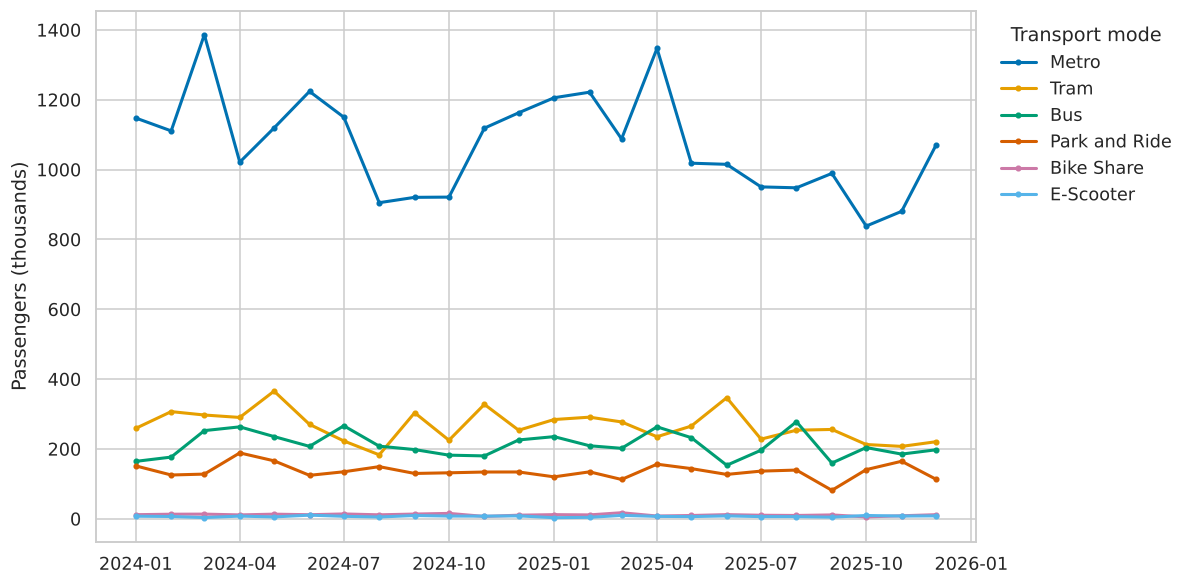

Year
2024    20974355
2025    19935366
Name: Passengers, dtype: int64
Change 2024->2025: -5.0%
Busiest month: Mar 2024 2080100
Quietest month: Oct 2025 1409837


Date
1     8847.0
2     9232.0
3     8805.0
4     9354.0
5     8729.0
6     8686.0
7     7984.0
8     7068.0
9     7411.0
10    6805.0
11    7559.0
12    7922.0
Name: Passengers, dtype: float64

In [5]:
monthly = df.groupby(["Month", "Transport_Mode"])["Passengers"].sum().reset_index()
mode_order = df.groupby("Transport_Mode")["Passengers"].sum().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 5.5))
for colour, mode in zip(OKABE, mode_order):
    d = monthly[monthly["Transport_Mode"] == mode]
    ax.plot(d["Month"], d["Passengers"] / 1000, marker="o", markersize=3, lw=2, color=colour, label=mode)
ax.set_ylabel("Passengers (thousands)")
ax.set_xlabel("")
ax.legend(title="Transport mode", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig("figures/fig1_timeseries.png", dpi=200, bbox_inches="tight")
plt.show()

yearly = df.groupby("Year")["Passengers"].sum()
print(yearly)
print("Change 2024->2025: {:.1f}%".format((yearly[2025] / yearly[2024] - 1) * 100))
m = df.groupby("Month")["Passengers"].sum()
print("Busiest month:", m.idxmax().strftime("%b %Y"), int(m.max()))
print("Quietest month:", m.idxmin().strftime("%b %Y"), int(m.min()))
df.groupby(df["Date"].dt.month)["Passengers"].mean().round(0)

## 6. Visualisation 2 – Comparison: passenger demand by city (Figure 6)

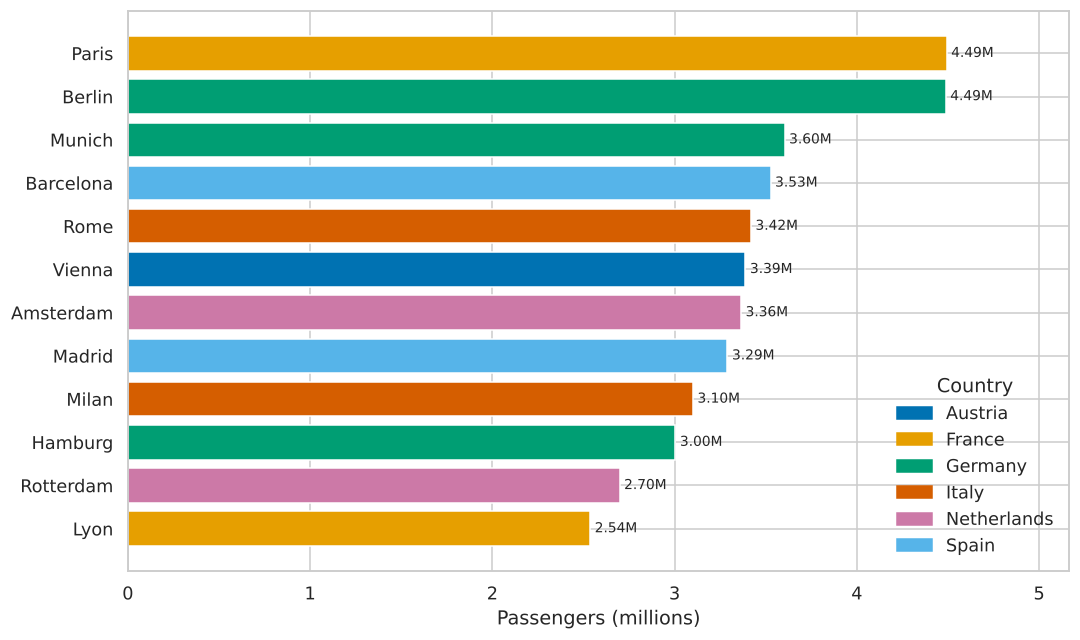

,City,Country,Passengers
8,Paris,France,4492481
2,Berlin,Germany,4487351
7,Munich,Germany,3603328
1,Barcelona,Spain,3526320
9,Rome,Italy,3418626
11,Vienna,Austria,3388470
0,Amsterdam,Netherlands,3364412
5,Madrid,Spain,3289904
6,Milan,Italy,3100424
3,Hamburg,Germany,3004164


In [6]:
city = (df.groupby(["City", "Country"])["Passengers"].sum()
          .reset_index().sort_values("Passengers"))
countries = sorted(df["Country"].unique())
cmap = dict(zip(countries, OKABE))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(city["City"], city["Passengers"] / 1e6, color=city["Country"].map(cmap))
ax.bar_label(bars, labels=[f"{v/1e6:.2f}M" for v in city["Passengers"]], padding=3, fontsize=9)
ax.set_xlabel("Passengers (millions)")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap[c]) for c in countries]
ax.legend(handles, countries, title="Country", loc="lower right", frameon=False)
ax.set_xlim(0, city["Passengers"].max() / 1e6 * 1.15)
plt.tight_layout()
plt.savefig("figures/fig2_city_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

city.sort_values("Passengers", ascending=False)

## 7. Visualisation 3 – Relationship: correlation heatmap of the 5 key KPIs (Figure 8)

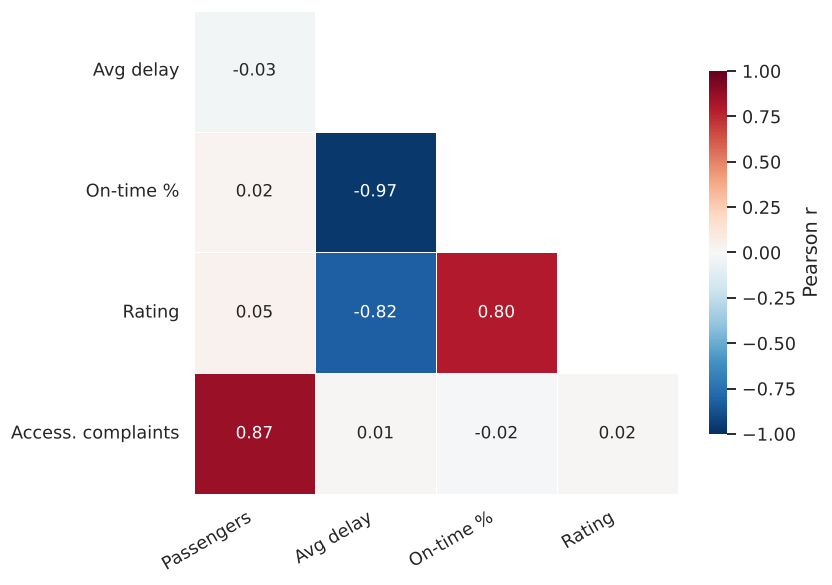

,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
Passengers,1.00,-0.33,-0.03,0.02,1.00,0.98,0.99,0.99,0.05,0.87
Trips,-0.33,1.00,-0.54,0.52,-0.33,-0.20,-0.28,-0.36,0.40,-0.30
Average_Delay_Minutes,-0.03,-0.54,1.00,-0.97,-0.04,-0.11,-0.07,0.01,-0.82,0.01
On_Time_Percentage,0.02,0.52,-0.97,1.00,0.03,0.11,0.07,-0.01,0.80,-0.02
Ticket_Revenue_EUR,1.00,-0.33,-0.04,0.03,1.00,0.98,0.98,0.98,0.05,0.86
Operating_Cost_EUR,0.98,-0.20,-0.11,0.11,0.98,1.00,0.98,0.96,0.11,0.85
CO2_Saved_KG,0.99,-0.28,-0.07,0.07,0.98,0.98,1.00,0.98,0.08,0.85
Energy_Consumption_KWh,0.99,-0.36,0.01,-0.01,0.98,0.96,0.98,1.00,0.02,0.86
Customer_Rating,0.05,0.40,-0.82,0.80,0.05,0.11,0.08,0.02,1.00,0.02
Accessibility_Complaints,0.87,-0.30,0.01,-0.02,0.86,0.85,0.85,0.86,0.02,1.00


In [7]:
all_cols = ["Passengers", "Trips", "Average_Delay_Minutes", "On_Time_Percentage",
            "Ticket_Revenue_EUR", "Operating_Cost_EUR", "CO2_Saved_KG",
            "Energy_Consumption_KWh", "Customer_Rating", "Accessibility_Complaints"]
corr_all = df[all_cols].corr()

key_cols = ["Passengers", "Average_Delay_Minutes", "On_Time_Percentage",
            "Customer_Rating", "Accessibility_Complaints"]
labels = ["Passengers", "Avg delay", "On-time %", "Rating", "Access. complaints"]
corr = df[key_cols].corr()
corr.index, corr.columns = labels, labels

corr_lower = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(corr_lower, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(corr_lower, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, annot_kws={"size": 11},
            cbar_kws={"shrink": 0.75, "label": "Pearson r"},
            ax=ax)
ax.grid(False)
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/fig3_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

corr_all.round(2)

## 8. Visualisation 4 – Distribution: delay minutes by weather condition (Figure 10)

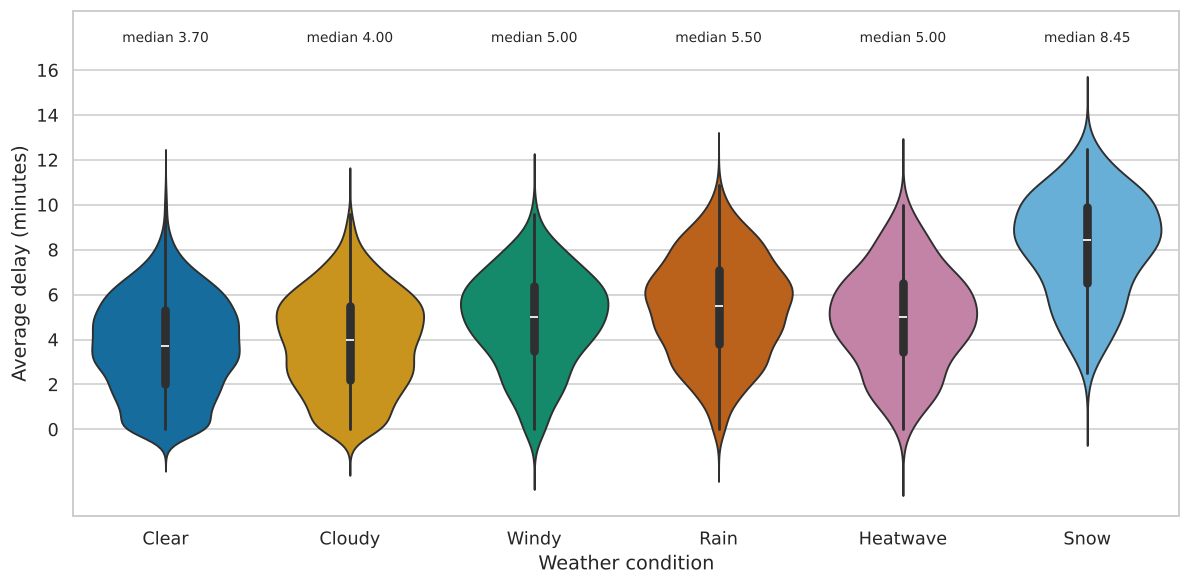

Average_Delay_Minutes        On_Time_Percentage       
                          mean median               mean median
Weather                                                        
Clear                     3.71   3.70              84.17  84.00
Cloudy                    3.89   4.00              83.46  83.30
Windy                     4.86   5.00              80.42  80.10
Rain                      5.40   5.50              78.70  78.30
Heatwave                  4.91   5.00              80.19  80.10
Snow                      8.14   8.45              69.97  69.15

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.5))
plot_df = df.assign(Weather=df["Weather"].astype(str))
weather_colours = dict(zip(weather_order, OKABE[:6]))
sns.violinplot(data=plot_df, x="Weather", y="Average_Delay_Minutes", order=weather_order,
               hue="Weather", hue_order=weather_order, palette=weather_colours,
               legend=False, inner="box", cut=4, ax=ax)
bottom, top = ax.get_ylim()
med = df.groupby("Weather", observed=True)["Average_Delay_Minutes"].median()
for i, w in enumerate(weather_order):
    ax.text(i, top + 0.6, f"median {med[w]:.2f}", ha="center", fontsize=9)
ax.set_ylim(bottom, top + 2)
ax.set_yticks(range(0, int(top) + 1, 2))
ax.set_ylabel("Average delay (minutes)")
ax.set_xlabel("Weather condition")
plt.tight_layout()
plt.savefig("figures/fig4_delay_weather.png", dpi=200, bbox_inches="tight")
plt.show()

df.groupby("Weather", observed=True)[
    ["Average_Delay_Minutes", "On_Time_Percentage"]].agg(["mean", "median"]).round(2)

In [9]:
df.groupby("Event_Day")[["Passengers", "Average_Delay_Minutes", "On_Time_Percentage",
                         "Customer_Rating", "Accessibility_Complaints"]].mean().round(2)

,Passengers,Average_Delay_Minutes,On_Time_Percentage,Customer_Rating,Accessibility_Complaints
Event_Day,,,,,
No,7968.86,4.22,82.49,4.02,12.17
Yes,10057.93,5.53,78.21,3.87,15.68


## 9. Visualisation 5 – Performance indicators: cost recovery and CO2 saved by mode (Figure 12)

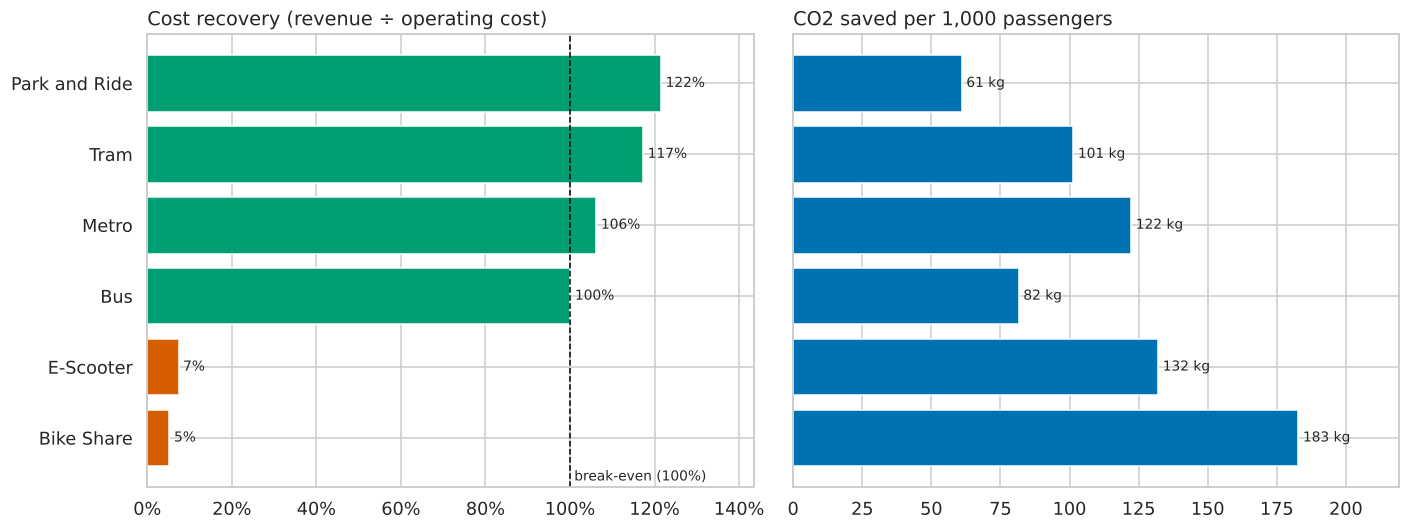

,Revenue,Cost,CO2,Pax,Rating,OnTime,Cost_Recovery_%,CO2_per_1k_Pax_KG
Transport_Mode,,,,,,,,
Bike Share,310355.03,5912287.24,49132.7,268765,4.35,90.85,5.25,182.81
E-Scooter,261278.13,3536959.56,21651.3,163942,4.29,89.71,7.39,132.07
Bus,12002118.92,11992457.44,414163.1,5073394,3.74,74.92,100.08,81.63
Metro,73334170.86,69029226.89,3150917.3,25757522,4.09,84.09,106.24,122.33
Tram,15666167.52,13355946.79,646918.7,6380878,3.94,80.63,117.30,101.38
Park and Ride,10066523.80,8283138.05,199191.2,3265220,3.90,79.46,121.53,61.00


In [10]:
kpi = df.groupby("Transport_Mode").agg(
    Revenue=("Ticket_Revenue_EUR", "sum"),
    Cost=("Operating_Cost_EUR", "sum"),
    CO2=("CO2_Saved_KG", "sum"),
    Pax=("Passengers", "sum"),
    Rating=("Customer_Rating", "mean"),
    OnTime=("On_Time_Percentage", "mean"))
kpi["Cost_Recovery_%"] = kpi["Revenue"] / kpi["Cost"] * 100
kpi["CO2_per_1k_Pax_KG"] = kpi["CO2"] / kpi["Pax"] * 1000
kpi = kpi.sort_values("Cost_Recovery_%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
colours = ["#D55E00" if v < 100 else "#009E73" for v in kpi["Cost_Recovery_%"]]
b1 = ax1.barh(kpi.index, kpi["Cost_Recovery_%"], color=colours)
ax1.axvline(100, color="black", ls="--", lw=1)
ax1.text(101, -0.6, "break-even (100%)", fontsize=9)
ax1.bar_label(b1, fmt="%.0f%%", padding=3, fontsize=9)
ax1.set_title("Cost recovery (revenue ÷ operating cost)", loc="left")
ax1.set_xlim(0, kpi["Cost_Recovery_%"].max() * 1.18)
ax1.xaxis.set_major_formatter(mtick.PercentFormatter())

b2 = ax2.barh(kpi.index, kpi["CO2_per_1k_Pax_KG"], color="#0072B2")
ax2.bar_label(b2, fmt="%.0f kg", padding=3, fontsize=9)
ax2.set_title("CO2 saved per 1,000 passengers", loc="left")
ax2.set_xlim(0, kpi["CO2_per_1k_Pax_KG"].max() * 1.2)

plt.tight_layout()
plt.savefig("figures/fig5_kpi_mode.png", dpi=200, bbox_inches="tight")
plt.show()

kpi.round(2)

## 10. Visualisation 6 – Accessibility: complaints per 1,000 passengers, city × route type (Figure 14)

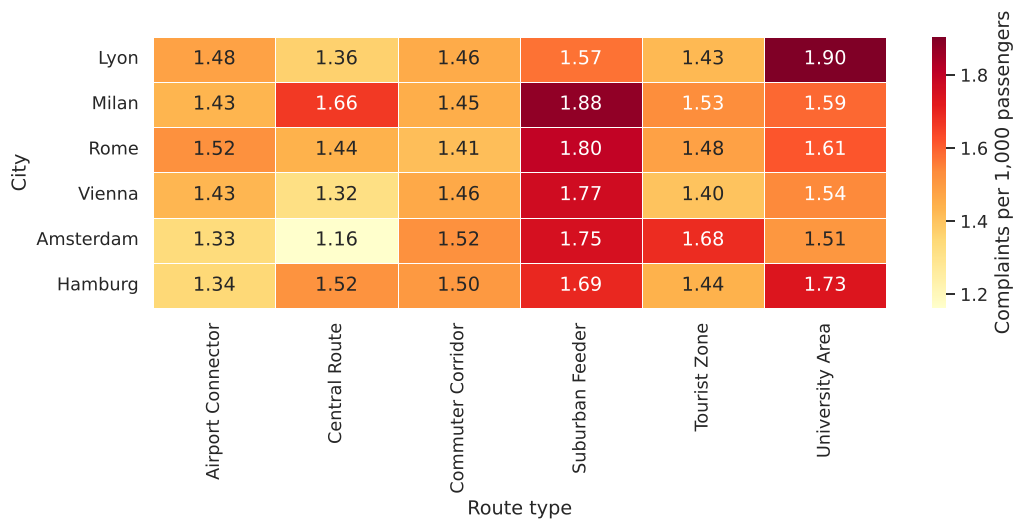

Transport_Mode
E-Scooter        1.84
Bus              1.75
Bike Share       1.70
Park and Ride    1.59
Tram             1.51
Metro            1.48
dtype: float64


In [11]:
acc = df.groupby(["City", "Route_Type"]).agg(C=("Accessibility_Complaints", "sum"),
                                              P=("Passengers", "sum"))
acc["Rate"] = acc["C"] / acc["P"] * 1000
pivot = acc["Rate"].unstack()

pivot = pivot.loc[pivot.max(axis=1).sort_values(ascending=False).index[:6]]

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "Complaints per 1,000 passengers"}, ax=ax)
ax.set_xlabel("Route type"); ax.set_ylabel("City")
plt.tight_layout()
plt.savefig("figures/fig6_accessibility.png", dpi=200, bbox_inches="tight")
plt.show()

mode_rate = (df.groupby("Transport_Mode")[["Accessibility_Complaints", "Passengers"]].sum()
               .eval("Accessibility_Complaints / Passengers * 1000"))
print(mode_rate.sort_values(ascending=False).round(2))

## 11. Supplementary chart – Punctuality vs customer rating (interactive)

In [12]:
import plotly.express as px

agg = df.groupby(["City", "Transport_Mode"]).agg(
    OnTime=("On_Time_Percentage", "mean"), Rating=("Customer_Rating", "mean"),
    Pax=("Passengers", "sum")).reset_index()
fig = px.scatter(agg, x="OnTime", y="Rating", size="Pax", color="Transport_Mode",
                 hover_name="City", color_discrete_sequence=OKABE, size_max=40,
                 labels={"OnTime": "Mean on-time %", "Rating": "Mean customer rating (1–5)",
                         "Transport_Mode": "Mode"},
                 title="Supplementary chart: On-time performance vs customer rating (city × mode, bubble = passengers)")
fig.update_layout(template="plotly_white", height=550)
fig.show()
print("r(on-time, rating) row level:", round(df["On_Time_Percentage"].corr(df["Customer_Rating"]), 3))

r(on-time, rating) row level: 0.797


## 12. Interactive dashboard (Plotly Dash) – Figures 16 and 17
Run this cell, then open **http://127.0.0.1:8050** in Chrome. Press the **Interrupt** (■) button to stop it.

In [13]:
from dash import Dash, dcc, html, Input, Output
import plotly.express as px

app = Dash(__name__)
app.title = "EcoMove Mobility Dashboard"

def kpi_card(id_, label):
    return html.Div([html.Div(label, style={"fontSize": "13px", "color": "#555"}),
                     html.Div(id=id_, style={"fontSize": "24px", "fontWeight": "bold"})],
                    style={"flex": "1", "padding": "12px", "margin": "4px", "background": "#f4f6f8",
                           "borderRadius": "8px", "borderLeft": "5px solid #0072B2"})

def dropdown(id_, col, label):
    opts = sorted(df[col].astype(str).unique())
    return html.Div([html.Label(label, style={"fontWeight": "bold"}),
                     dcc.Dropdown(opts, [], multi=True, id=id_, placeholder="All")],
                    style={"flex": "1", "margin": "4px"})

app.layout = html.Div(style={"fontFamily": "Arial", "padding": "16px", "maxWidth": "1400px"}, children=[
    html.H2("EcoMove City Transport Authority – Sustainable Mobility Dashboard"),
    html.Div([dropdown("f_country", "Country", "Country"),
              dropdown("f_city", "City", "City"),
              dropdown("f_mode", "Transport_Mode", "Transport mode"),
              dropdown("f_route", "Route_Type", "Route type"),
              dropdown("f_weather", "Weather", "Weather"),
              html.Div([html.Label("Event day", style={"fontWeight": "bold"}),
                        dcc.RadioItems(["All", "Yes", "No"], "All", id="f_event", inline=True)],
                       style={"flex": "1", "margin": "4px"})],
             style={"display": "flex", "flexWrap": "wrap"}),
    html.Div([html.Label("Date range", style={"fontWeight": "bold"}),
              dcc.DatePickerRange(id="f_date", start_date=df["Date"].min(), end_date=df["Date"].max(),
                                  display_format="DD/MM/YYYY")], style={"margin": "8px 4px"}),
    html.Div([kpi_card("k_pax", "Passengers"), kpi_card("k_ontime", "Avg on-time %"),
              kpi_card("k_delay", "Avg delay (min)"), kpi_card("k_rating", "Avg rating"),
              kpi_card("k_recovery", "Cost recovery"), kpi_card("k_co2", "CO2 saved (tonnes)"),
              kpi_card("k_access", "Access. complaints / 1k pax")],
             style={"display": "flex", "flexWrap": "wrap"}),
    html.Div([dcc.Graph(id="g_trend", style={"flex": "1", "minWidth": "600px"}),
              dcc.Graph(id="g_city", style={"flex": "1", "minWidth": "600px"})],
             style={"display": "flex", "flexWrap": "wrap"}),
    html.Div([dcc.Graph(id="g_mode", style={"flex": "1", "minWidth": "600px"}),
              dcc.Graph(id="g_delay", style={"flex": "1", "minWidth": "600px"})],
             style={"display": "flex", "flexWrap": "wrap"}),
])

@app.callback(
    [Output("k_pax", "children"), Output("k_ontime", "children"), Output("k_delay", "children"),
     Output("k_rating", "children"), Output("k_recovery", "children"), Output("k_co2", "children"),
     Output("k_access", "children"),
     Output("g_trend", "figure"), Output("g_city", "figure"),
     Output("g_mode", "figure"), Output("g_delay", "figure")],
    [Input("f_country", "value"), Input("f_city", "value"), Input("f_mode", "value"),
     Input("f_route", "value"), Input("f_weather", "value"), Input("f_event", "value"),
     Input("f_date", "start_date"), Input("f_date", "end_date")])
def update(country, city, mode, route, weather, event, start, end):
    d = df[(df["Date"] >= start) & (df["Date"] <= end)]
    for col, val in [("Country", country), ("City", city), ("Transport_Mode", mode),
                     ("Route_Type", route), ("Weather", weather)]:
        if val:
            d = d[d[col].astype(str).isin(val)]
    if event != "All":
        d = d[d["Event_Day"] == event]
    if d.empty:
        empty = px.scatter(title="No data for this selection")
        return ["-"] * 7 + [empty] * 4

    kpis = [f"{d['Passengers'].sum():,.0f}", f"{d['On_Time_Percentage'].mean():.1f}%",
            f"{d['Average_Delay_Minutes'].mean():.2f}", f"{d['Customer_Rating'].mean():.2f} / 5",
            f"{d['Ticket_Revenue_EUR'].sum() / d['Operating_Cost_EUR'].sum() * 100:.0f}%",
            f"{d['CO2_Saved_KG'].sum() / 1000:,.0f}",
            f"{d['Accessibility_Complaints'].sum() / d['Passengers'].sum() * 1000:.2f}"]

    t = d.groupby("Month").agg(Passengers=("Passengers", "sum"),
                               OnTime=("On_Time_Percentage", "mean")).reset_index()
    f1 = px.line(t, x="Month", y="Passengers", markers=True, title="Monthly passengers")

    c = d.groupby("City").agg(Passengers=("Passengers", "sum"),
                              Rating=("Customer_Rating", "mean")).reset_index().sort_values("Passengers")
    f2 = px.bar(c, x="Passengers", y="City", orientation="h", color="Rating",
                color_continuous_scale="Blues", title="Passengers by city (colour = avg rating)")

    m = d.groupby("Transport_Mode").agg(Rev=("Ticket_Revenue_EUR", "sum"),
                                        Cost=("Operating_Cost_EUR", "sum")).reset_index()
    m = m.melt(id_vars="Transport_Mode", value_vars=["Rev", "Cost"], var_name="Measure", value_name="EUR")
    m["Measure"] = m["Measure"].map({"Rev": "Ticket revenue", "Cost": "Operating cost"})
    f3 = px.bar(m, x="Transport_Mode", y="EUR", color="Measure", barmode="group",
                color_discrete_sequence=["#009E73", "#D55E00"], title="Revenue vs operating cost by mode")

    f4 = px.box(d, x="Route_Type", y="Average_Delay_Minutes", color="Route_Type",
                color_discrete_sequence=OKABE, title="Delay distribution by route type")
    f4.update_layout(showlegend=False)

    for f in (f1, f2, f3, f4):
        f.update_layout(template="plotly_white", height=380, margin=dict(l=40, r=20, t=50, b=40))
    return kpis + [f1, f2, f3, f4]

app.run(jupyter_mode="external", port=8050, debug=False)

Dash app running on http://127.0.0.1:8050/
